# Introduction to Time Series Analysis

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is a Time Series?

A **time series** is a sequence of observations recorded **at regular time intervals**, e.g. daily stock prices, monthly rainfall or yearly population.

Unlike the data in earlier lessons, observations are **not independent**: today's value is related to yesterday's. Key characteristics:
- **Trend**: long-term increase or decrease
- **Seasonality**: repeating patterns at fixed intervals (e.g. every 12 months)
- **Noise**: random fluctuations

## 2. Components of a Time Series

Additive model:
$$
y_t = T_t + S_t + R_t
$$
where $T_t$ is the trend, $S_t$ the seasonal component and $R_t$ the residual (noise).

When seasonal swings grow with the level of the series, a **multiplicative** model fits better:
$$
y_t = T_t \times S_t \times R_t
$$

## 3. Stationarity and Autocorrelation

A series is **stationary** if its mean, variance and autocorrelation structure do not change over time. Many forecasting models (e.g. ARIMA) require stationarity; non-stationary series can be transformed by **differencing** ($y_t - y_{t-1}$), log transforms or de-trending.

The **autocorrelation** at lag $k$ measures the correlation of a series with its own past:
$$
\rho_k = \frac{\text{Cov}(y_t, y_{t-k})}{\text{Var}(y_t)}
$$

In [2]:
# Simulate 4 years of monthly data: trend + seasonality + noise
set.seed(123)
time_points <- 1:48
trend  <- 0.5 * time_points
season <- 10 * sin(2 * pi * time_points / 12)
noise  <- rnorm(48, mean = 0, sd = 3)
ts_data <- trend + season + noise

ts_series <- ts(ts_data, frequency = 12, start = c(2020, 1))
print(round(ts_series, 2))

       Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
2020  3.82  8.97 16.18 10.87  7.89  8.15 -0.12 -8.46 -7.56 -5.00  4.17  7.08
2021 12.70 15.99 15.83 22.02 14.99  3.10  6.60 -0.08 -2.70  1.69  3.42  9.81
2022 15.62 16.60 26.01 23.12 16.09 18.76 11.78  6.45  9.19 10.97 14.96 20.07
2023 25.16 27.47 28.58 27.52 23.42 20.38 12.70 19.85 16.12 10.97 17.29 22.60


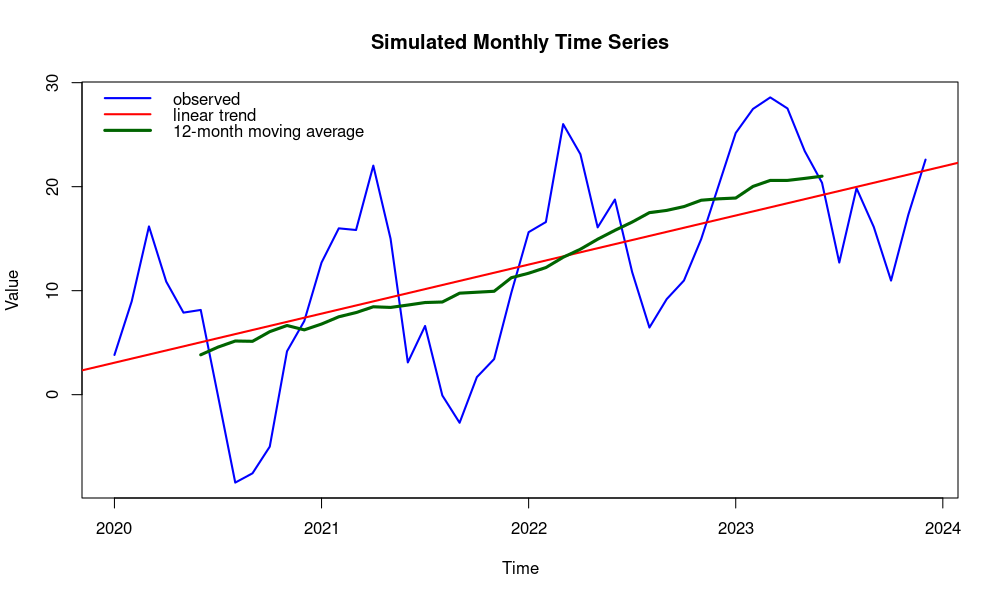

In [3]:
plot(ts_series, main = "Simulated Monthly Time Series", xlab = "Time", ylab = "Value", col = "blue", lwd = 2)
abline(lm(ts_series ~ time(ts_series)), col = "red", lwd = 2)
lines(stats::filter(ts_series, rep(1 / 12, 12), sides = 2), col = "darkgreen", lwd = 3)
legend("topleft", c("observed", "linear trend", "12-month moving average"),
       col = c("blue", "red", "darkgreen"), lwd = c(2, 2, 3), bty = "n")

## 4. Decomposition

`decompose()` estimates the trend with a centred moving average, the seasonal component by averaging each month's deviation from the trend, and leaves the rest as the residual.

Estimated seasonal effect per month:


 [1]   5.74   7.36  10.10  10.29   3.83  -0.65  -3.43 -10.77 -10.86  -8.35
[11]  -3.83   0.58


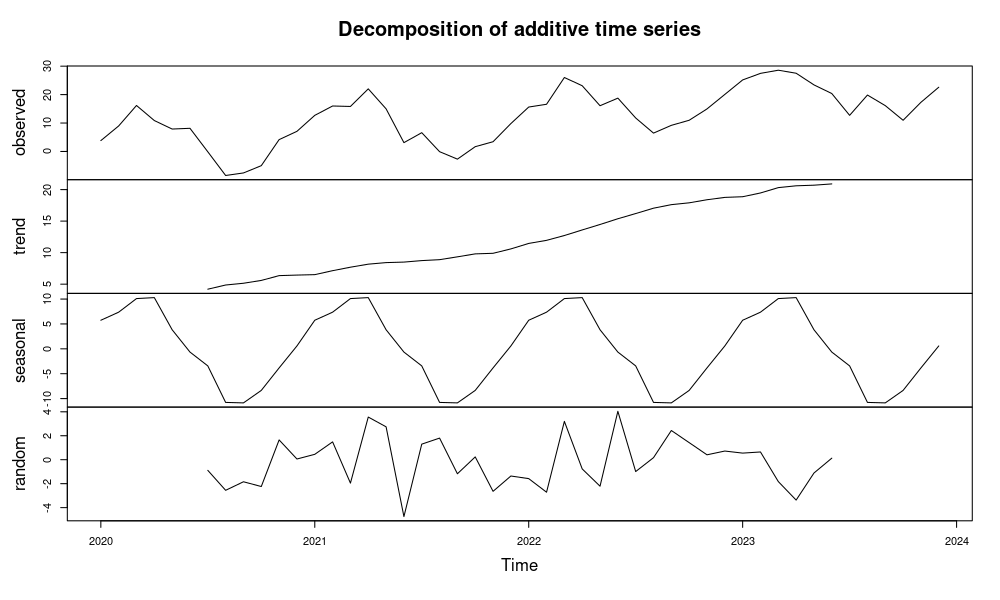

In [4]:
ts_decomp <- decompose(ts_series)
plot(ts_decomp)
cat("Estimated seasonal effect per month:\n")
print(round(ts_decomp$figure, 2))

## 5. Autocorrelation and Differencing

The ACF of the raw series decays slowly and oscillates (trend + seasonality → non-stationary). After **seasonal differencing** ($y_t - y_{t-12}$) and a first difference, most autocorrelations fall inside the blue significance bands.

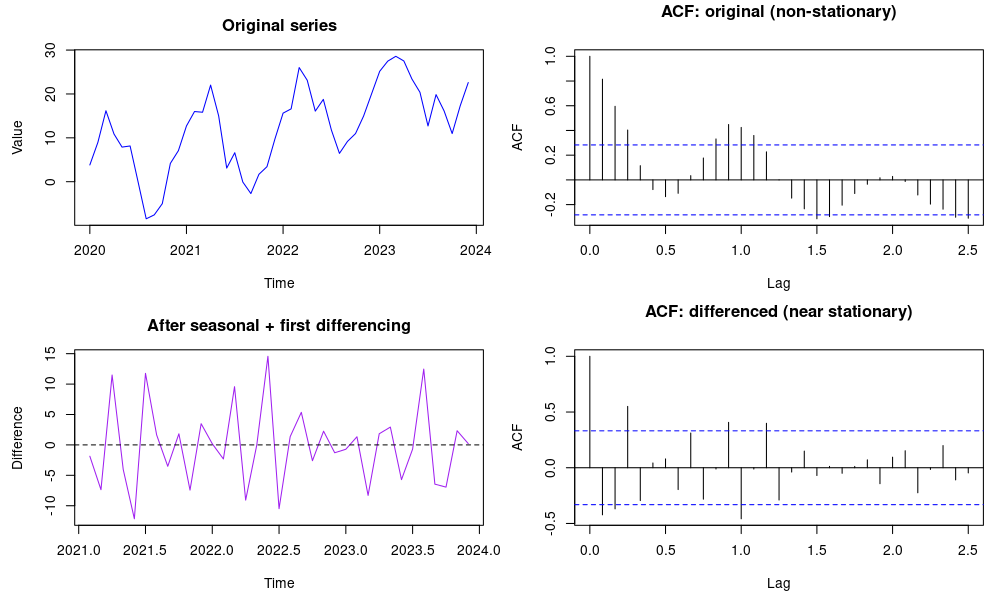

In [5]:
diffed <- diff(diff(ts_series, lag = 12))

par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3, 1))
plot(ts_series, main = "Original series", ylab = "Value", col = "blue")
acf(ts_series, lag.max = 30, main = "ACF: original (non-stationary)")
plot(diffed, main = "After seasonal + first differencing", ylab = "Difference", col = "purple")
abline(h = 0, lty = 2)
acf(diffed, lag.max = 30, main = "ACF: differenced (near stationary)")

## 6. A First Forecast: Holt–Winters

Holt–Winters exponential smoothing tracks level, trend and seasonality, giving more weight to recent observations. We hold out the last 12 months to measure forecast accuracy honestly.

Holt-Winters MAE on the 12 held-out months      : 4.48 


Seasonal-naive MAE ('same month last year')      : 5.2 


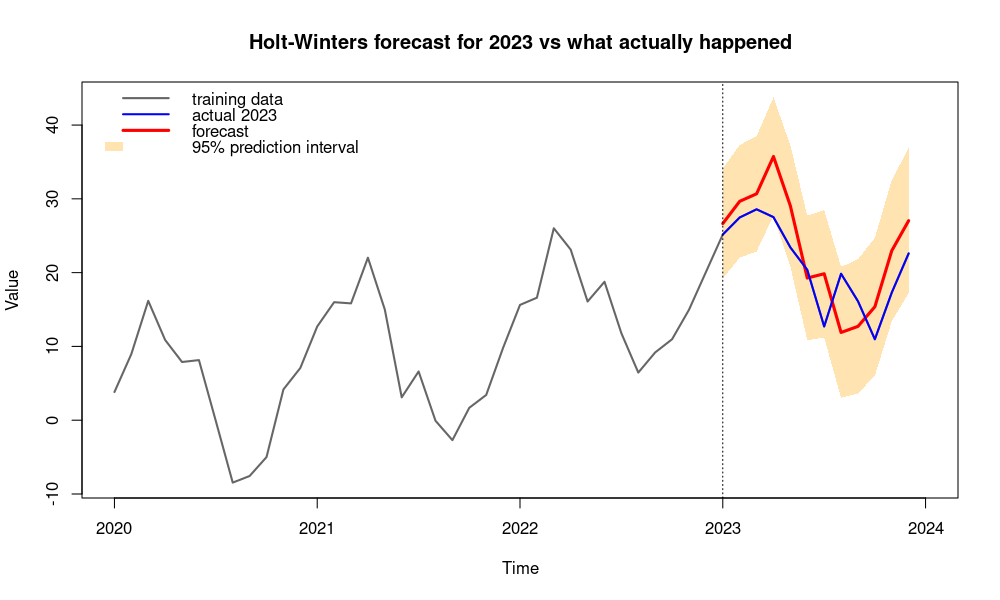

In [6]:
train <- window(ts_series, end = c(2022, 12))
test  <- window(ts_series, start = c(2023, 1))

hw_fit <- HoltWinters(train)
fc <- predict(hw_fit, n.ahead = 12, prediction.interval = TRUE)

naive_seasonal <- window(train, start = c(2022, 1))      # "same month last year"
mae <- function(a, f) mean(abs(as.numeric(a) - as.numeric(f)))   # compare values, not time indices
cat("Holt-Winters MAE on the 12 held-out months      :", round(mae(test, fc[, "fit"]), 2), "\n")
cat("Seasonal-naive MAE ('same month last year')      :", round(mae(test, naive_seasonal), 2), "\n")

par(mfrow = c(1, 1))
plot(ts_series, xlim = c(2020, 2024), ylim = range(c(ts_series, fc)), lwd = 2, col = "grey40",
     main = "Holt-Winters forecast for 2023 vs what actually happened", ylab = "Value")
polygon(c(time(fc), rev(time(fc))), c(fc[, "lwr"], rev(fc[, "upr"])), col = adjustcolor("orange", 0.3), border = NA)
lines(fc[, "fit"], col = "red", lwd = 3)
lines(test, col = "blue", lwd = 2)
abline(v = 2023, lty = 3)
legend("topleft", c("training data", "actual 2023", "forecast", "95% prediction interval"),
       col = c("grey40", "blue", "red", NA), lwd = c(2, 2, 3, NA),
       fill = c(NA, NA, NA, adjustcolor("orange", 0.3)), border = NA, bty = "n")

*Insight: Always compare a forecast against a simple baseline such as "same month last year". A sophisticated model that can't beat the naive forecast isn't adding value. Module M17 (Time Series & Forecasting) builds on this with ARIMA, Prophet and proper backtesting.*

## Real-World Use Case or Analogy

Imagine tracking monthly electricity consumption:

- **Trend**: a gradual increase in consumption as the population grows.
- **Seasonality**: higher usage in winter and summer (heating and cooling).
- **Noise**: random events — a heat wave, a holiday, a factory shutdown.

Decomposition is like listening to a song and separating the **bass line** (trend), the **chorus that repeats** (seasonality) and the **crowd noise** (residual). Once you can hear each part separately, predicting what comes next becomes much easier.